In [ ]:

# ============================================================
# GROUP NORMALIZATION
# ============================================================

# 1. Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf




In [6]:
tf.keras.utils.set_random_seed(42)

# 2. Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

x_train = x_train[:12000].astype("float32") / 255.0
y_train = y_train[:12000]

x_test = x_test[:2000].astype("float32") / 255.0
y_test = y_test[:2000]

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

# 3. Create Group Normalization Layer
class GroupNorm(tf.keras.layers.Layer):

    def __init__(self, groups=4, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.groups = groups
        self.epsilon = epsilon

    def build(self, input_shape):

        channels = input_shape[-1]

        if channels % self.groups != 0:
            raise ValueError(
                "Channels must be divisible by groups."
            )

        self.channels_per_group = channels // self.groups

        self.gamma = self.add_weight(
            name="gamma",
            shape=(channels,),
            initializer="ones",
            trainable=True
        )

        self.beta = self.add_weight(
            name="beta",
            shape=(channels,),
            initializer="zeros",
            trainable=True
        )

    def call(self, inputs):

        shape = tf.shape(inputs)

        # Reshape channels into groups
        grouped = tf.reshape(
            inputs,
            [
                shape[0],
                shape[1],
                shape[2],
                self.groups,
                self.channels_per_group
            ]
        )

        # Normalize spatial dimensions and channels per group
        mean, variance = tf.nn.moments(
            grouped,
            axes=[1, 2, 4],
            keepdims=True
        )

        normalized = (
            (grouped - mean)
            * tf.math.rsqrt(variance + self.epsilon)
        )

        # Restore original shape
        normalized = tf.reshape(normalized, shape)

        return (
            normalized * self.gamma[None, None, None, :]
            + self.beta[None, None, None, :]
        )

    def get_config(self):

        config = super().get_config()
        config.update({
            "groups": self.groups,
            "epsilon": self.epsilon
        })

        return config

# 4. Test Group Normalization
dummy_input = tf.random.normal((4, 16, 16, 8))

group_layer = GroupNorm(groups=4)
dummy_output = group_layer(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

# 5. Build CNN Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        16, 3, padding="same", use_bias=False
    ),
    GroupNorm(groups=4),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        32, 3, padding="same", use_bias=False
    ),
    GroupNorm(groups=4),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (12000, 28, 28, 1)
Testing shape: (2000, 28, 28, 1)
Input shape: (4, 16, 16, 8)
Output shape: (4, 16, 16, 8)


In [7]:
# 6. Compile Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 7. Train Model
history = model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    verbose=1
)

# 8. Evaluate Model
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_norm_1 (GroupNorm)        │ (None, 28, 28, 16)     │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_norm_2 (GroupNorm)        │ (None, 14, 14, 32)     │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,914 (413.73 KB)

 Trainable params: 105,914 (413.73 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
169/169 ━━━━━━━━━━━━━━━━━━━━ 21s 110ms/step - accuracy: 0.8559 - loss: 0.4856 - val_accuracy: 0.9508 - val_loss: 0.1588
Epoch 2/5
169/169 ━━━━━━━━━━━━━━━━━━━━ 15s 89ms/step - accuracy: 0.9683 - loss: 0.1058 - val_accuracy: 0.9675 - val_loss: 0.1111
Epoch 3/5
169/169 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - accuracy: 0.9806 - loss: 0.0670 - val_accuracy: 0.9658 - val_loss: 0.1020
Epoch 4/5
169/169 ━━━━━━━━━━━━━━━━━━━━ 18s 88ms/step - accuracy: 0.9869 - loss: 0.0486 - val_accuracy: 0.9675 - val_loss: 0.0901
Epoch 5/5
169/169 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - accuracy: 0.9919 - loss: 0.0330 - val_accuracy: 0.9725 - val_loss: 0.0835

Test Loss: 0.0985
Test Accuracy: 0.9675


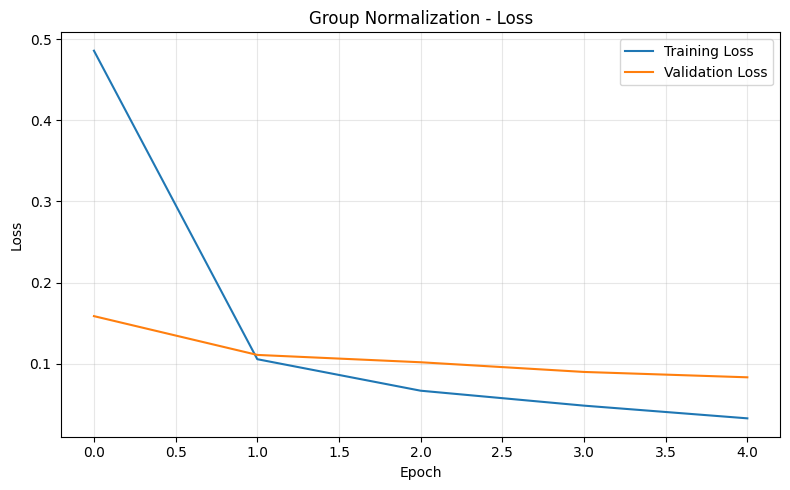

In [9]:
# 9. Plot Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Group Normalization - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



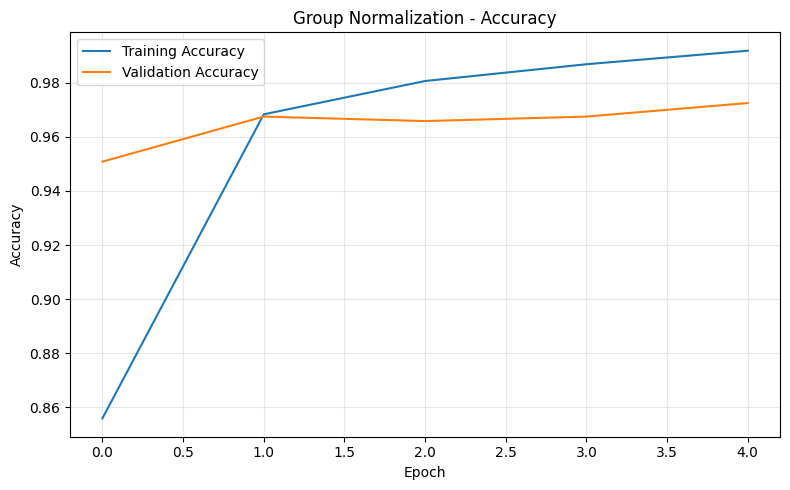

In [10]:
# 10. Plot Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Group Normalization - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()